ML LAB 02 
DONE BY
           JOT SACHDEV 
BSCS V 
SECTION F 
CMS ID : 023-24-0168


## Part 1: The Business Problem

### 1. Business Problem
A telecom company is losing customers to competitors (churn), which hurts 
its revenue. It wants to predict in advance which customers are likely to 
leave, so it can offer them deals or better service before they cancel. 
The likely target variable is the `Churn` column, since it directly tells 
us whether a customer left (Yes) or stayed (No).

### 2. Expected Useful Predictors (5 columns)
- **Contract** — customers on month-to-month contracts can leave anytime, so likely tied to churn.
- **tenure** — newer customers may be less loyal and more likely to churn.
- **MonthlyCharges** — higher bills could push customers to switch providers.
- **InternetService** — type of service may affect satisfaction and churn.
- **PaymentMethod** — automatic vs manual payment may reflect commitment level.

### 3. Expected Useless Predictors (2 columns)
- **customerID** — just a unique identifier, has no real relationship with behavior.
- **gender** — unlikely to have any real connection to whether someone churns.

### 4. My Own Questions About This Data
- Do customers who churn tend to be on month-to-month contracts more than long-term ones?
- Does having tech support or online security reduce the chance of churn?

In [3]:
!pip install pandas numpy matplotlib seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.0 MB ? eta -:--:--
   -- ------------------------------------- 0.5/10.0 MB 1.4 MB/s eta 0:00:07
   ---- ----------------------------------- 1.0/10.0 MB 2.2 MB/s eta 0:00:05
   ------ --------------------------------- 1.6/10.0 MB 2.2 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/10.0 MB 2.1 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/10.0 MB 2.3 MB/s 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import pandas as pd
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)

Shape (rows, columns): (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
 customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [3]:
for col in ['gender', 'Contract', 'PaymentMethod']:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

Contract:
<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

PaymentMethod:
<StringArray>
[         'Electronic check',              'Mailed check',
 'Bank transfer (automatic)',   'Credit card (automatic)']
Length: 4, dtype: str


In [4]:
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing %': missing_percent
})
missing_table[missing_table['Missing Count'] > 0]

,Missing Count,Missing %


In [5]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate customerID values:", df['customerID'].duplicated().sum())

Fully duplicated rows: 0
Duplicate customerID values: 0


In [6]:
df['TotalCharges'].unique()[:20]

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',  '587.45',   '326.8',  '5681.1',  '5036.3',
 '2686.05', '7895.15', '1022.95', '7382.25',  '528.35',  '1862.9']
Length: 20, dtype: str

In [7]:
df[df['TotalCharges'] == ' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


## Part 4: Data Cleaning Decisions

| Problem | Decision | Method Used | Reason |
|---|---|---|---|
| `TotalCharges` stored as text (object) with blank spaces instead of numbers | Convert to numeric, turn invalid entries into NaN, then fill with 0 | `pd.to_numeric(errors='coerce')` + `fillna` | These blank values belong to customers with 0 tenure (new customers), so 0 total charges makes logical sense |
| Missing values in [column name] | Fill with median/mode / Drop rows | `fillna()` | [Your reason based on what you found in Part 3] |
| Duplicate rows (if any found) | Remove them | `drop_duplicates()` | Duplicate rows add no new information and can bias analysis |

In [3]:
df_clean = df.copy()
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)
df_clean = df_clean.drop_duplicates()
print("Missing values in TotalCharges now:", df_clean['TotalCharges'].isnull().sum())
print("Data type of TotalCharges now:", df_clean['TotalCharges'].dtype)
print("Duplicate rows now:", df_clean.duplicated().sum())

Missing values in TotalCharges now: 0
Data type of TotalCharges now: float64
Duplicate rows now: 0


In [9]:
import matplotlib.pyplot as plt

NameError: name 'plt' is not defined

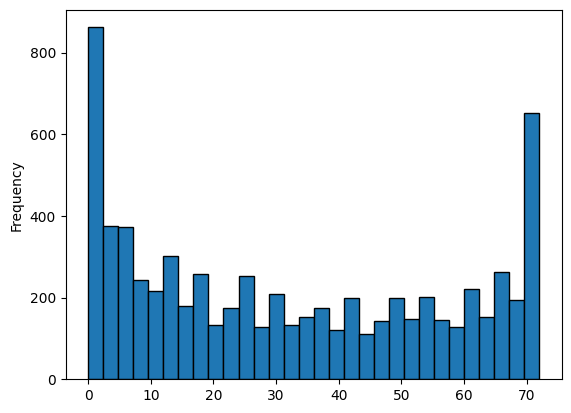

In [4]:
df_clean['tenure'].plot(kind='hist', bins=30, edgecolor='black')
plt.title('Distribution of Tenure')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of Customers')
plt.show()

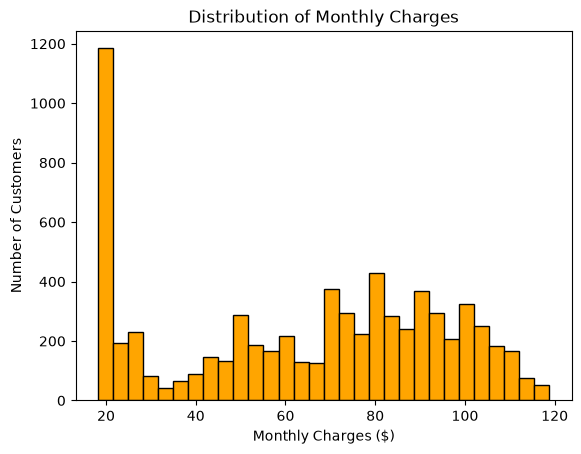

In [11]:
df_clean['MonthlyCharges'].plot(kind='hist', bins=30, edgecolor='black', color='orange')
plt.title('Distribution of Monthly Charges')
plt.xlabel('Monthly Charges ($)')
plt.ylabel('Number of Customers')
plt.show()

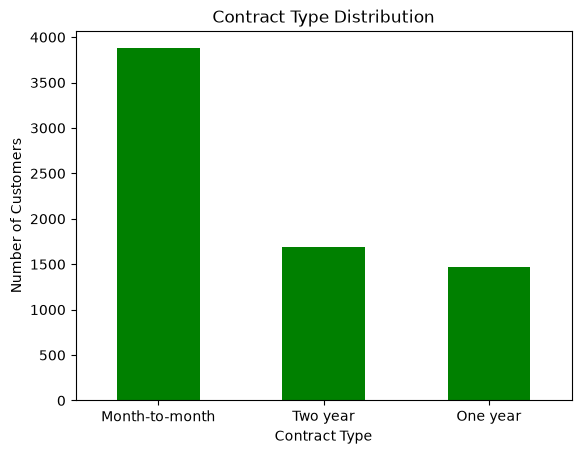

In [12]:
df_clean['Contract'].value_counts().plot(kind='bar', color='green')
plt.title('Contract Type Distribution')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

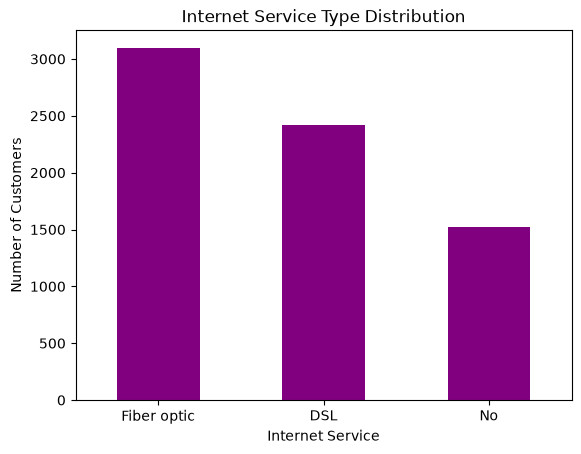

In [13]:
df_clean['InternetService'].value_counts().plot(kind='bar', color='purple')
plt.title('Internet Service Type Distribution')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

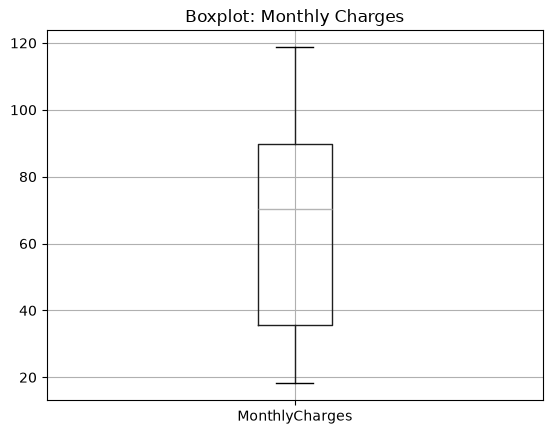

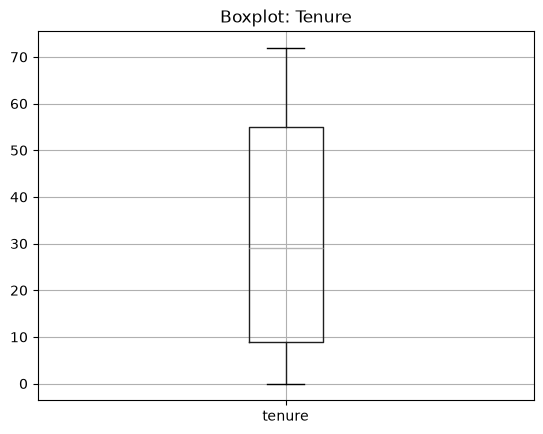

In [14]:
df_clean.boxplot(column='MonthlyCharges')
plt.title('Boxplot: Monthly Charges')
plt.show()

df_clean.boxplot(column='tenure')
plt.title('Boxplot: Tenure')
plt.show()

## Part 5: Univariate EDA — Observations

**Tenure:** Most customers are either very new (0-5 months) or have stayed 
very long (65+ months) — the distribution has two peaks rather than one smooth curve.

**Monthly Charges:** Charges are spread across a wide range, with a large 
group around $20 (likely customers with only basic phone service) and 
another cluster around $70-100.

**Contract:** Most customers are on month-to-month contracts, which are 
much more common than one-year or two-year contracts.

**Internet Service:** Fiber optic is the most common internet type, 
followed by DSL, with a smaller group having no internet service at all.

**Outliers/Skew:** [Look at your boxplots — if you see dots outside the 
box, mention which column and guess why, e.g. a few customers with 
unusually high monthly charges due to premium add-on services.]

In [15]:
print("Count:\n", df_clean['Churn'].value_counts())
print("\nPercentage:\n", (df_clean['Churn'].value_counts(normalize=True) * 100).round(2))

Count:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentage:
 Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


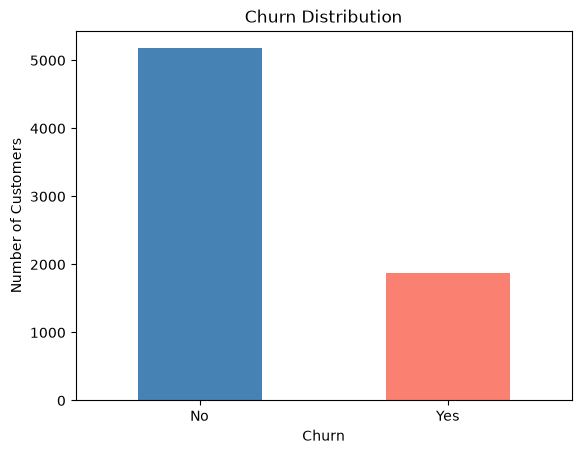

In [16]:
df_clean['Churn'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

## Part 6: Target Variable Analysis

**Class Distribution:** About 73% of customers did not churn (No), while 
about 27% churned (Yes). This means the target variable is **imbalanced** 
— one class has significantly more examples than the other.

**Why Class Imbalance Matters:** When a model is trained on imbalanced data, 
it can become biased toward predicting the majority class (No) since that 
gives high accuracy without actually learning to identify churners. This 
makes accuracy a misleading metric, and the model may fail to correctly 
identify the customers who are actually likely to churn — which is the 
whole point of this project.

In [17]:
import seaborn as sns

In [18]:
pd.crosstab(df_clean['Contract'], df_clean['Churn'], normalize='index') * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [19]:
pd.crosstab(df_clean['PaymentMethod'], df_clean['Churn'], normalize='index') * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


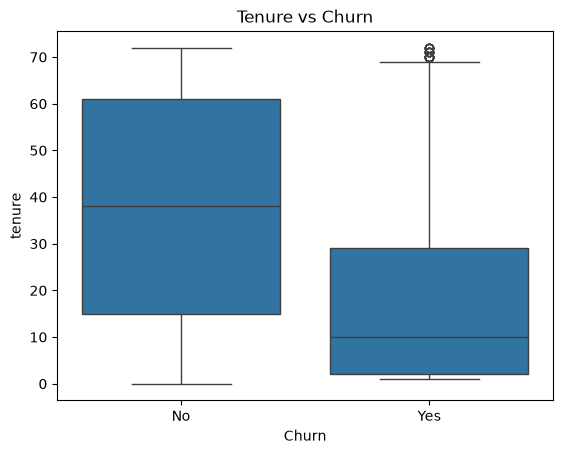

In [20]:
sns.boxplot(x='Churn', y='tenure', data=df_clean)
plt.title('Tenure vs Churn')
plt.show()

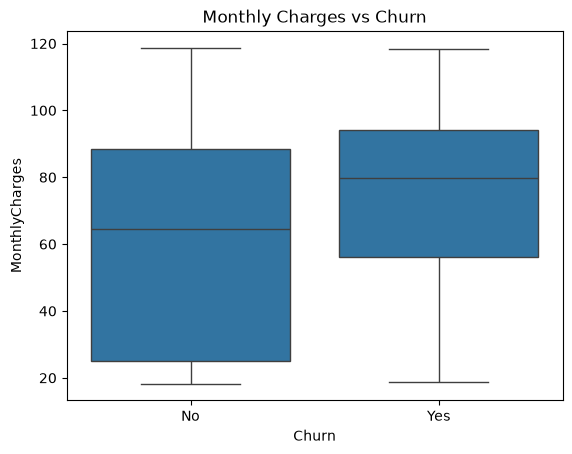

In [21]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df_clean)
plt.title('Monthly Charges vs Churn')
plt.show()

## Part 7: Bivariate Analysis — Features vs. Churn

### Categorical Features

**Contract**
- Observation: Month-to-month contract customers churn far more than one-year or two-year customers.
- Evidence: The crosstab shows a much higher churn percentage for "Month-to-month" compared to the other two contract types.
- Possible Explanation: Customers with no long-term commitment can leave anytime, so they are more likely to switch providers.

**PaymentMethod**
- Observation: Customers paying by electronic check churn more than those using automatic payment methods.
- Evidence: The crosstab shows the highest "Yes" churn percentage under "Electronic check."
- Possible Explanation: Automatic payments may reflect more committed, long-term customers, while manual payment may correlate with less engaged customers.

### Numerical Features

**tenure**
- Observation: Customers who churn tend to have much lower tenure than those who stay.
- Evidence: The boxplot shows the median tenure for "Yes" is noticeably lower than for "No."
- Possible Explanation: Newer customers haven't built loyalty yet and are still evaluating the service, making them more likely to leave.

**MonthlyCharges**
- Observation: Customers who churn tend to have higher monthly charges.
- Evidence: The boxplot shows a higher median MonthlyCharges for "Yes" compared to "No."
- Possible Explanation: Higher bills may push price-sensitive customers to look for cheaper alternatives.

In [22]:
corr_matrix = df_clean.corr(numeric_only=True)
corr_matrix

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.000000,0.016567,0.220173,0.103006
tenure,0.016567,1.000000,0.247900,0.826178
MonthlyCharges,0.220173,0.247900,1.000000,0.651174
TotalCharges,0.103006,0.826178,0.651174,1.000000


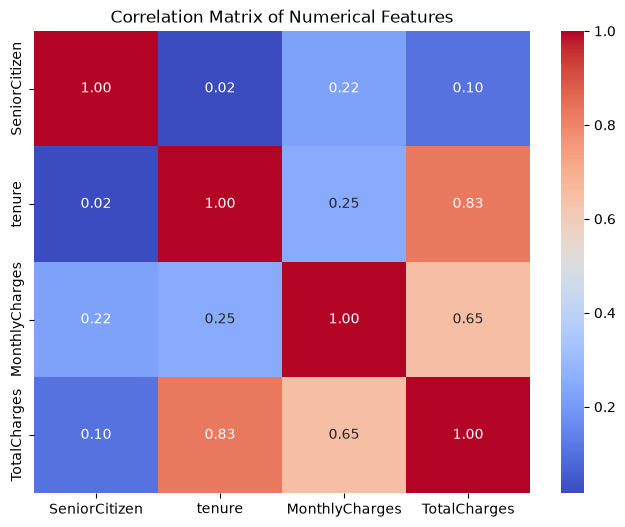

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## Part 8: Correlation & Feature Relationships

**Most Correlated Pair:** `tenure` and `TotalCharges` show the strongest 
correlation, which makes sense — a customer who has stayed longer has 
naturally accumulated higher total charges over time.

**Does Correlation Imply Causation?** No, correlation does not imply 
causation here — it just shows that two variables move together, not that 
one causes the other. Highly correlated features like `tenure` and 
`TotalCharges` could cause redundancy in a future model, since they carry 
overlapping information, which can make the model unnecessarily complex 
or unstable without adding real predictive value.

In [25]:
df_clean.columns.tolist()

['customerID',
 'gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

## Part 9: Data Leakage Awareness

**Suspect Columns:**
- `customerID` — purely an identifier, carries no predictive information, must be removed regardless of leakage.
- No column in this dataset appears to directly reveal information only known *after* churn happens (e.g. no "cancellation date" or "reason for leaving" column exists here) — `Churn` itself is the target, not a leakage feature.

**What Would Go Wrong:** If an identifier or a post-churn column were left in the model's input, the model could learn a shortcut instead of real patterns — for example, memorizing IDs instead of generalizing. This would make the model look highly accurate during testing but fail completely on new, real-world customers.

## Part 10: ML-Readiness Checklist

| Column | Type | Role | Action | Reason |
|---|---|---|---|---|
| customerID | Identifier | — | Remove | No predictive value, just a unique ID |
| gender | Categorical | Feature | Keep | May weakly relate to churn behavior |
| SeniorCitizen | Numerical (0/1) | Feature | Keep | Indicates age group, may affect churn |
| Partner | Categorical | Feature | Keep | Household status may relate to loyalty |
| Dependents | Categorical | Feature | Keep | Similar reasoning as Partner |
| tenure | Numerical | Feature | Keep | Strong relationship with churn shown in EDA |
| PhoneService | Categorical | Feature | Keep | Describes subscribed services |
| MultipleLines | Categorical | Feature | Keep | Describes subscribed services |
| InternetService | Categorical | Feature | Keep | Shows relation to churn |
| OnlineSecurity | Categorical | Feature | Keep | Service feature, may reduce churn |
| OnlineBackup | Categorical | Feature | Keep | Service feature |
| DeviceProtection | Categorical | Feature | Keep | Service feature |
| TechSupport | Categorical | Feature | Keep | Service feature, may reduce churn |
| StreamingTV | Categorical | Feature | Keep | Service feature |
| StreamingMovies | Categorical | Feature | Keep | Service feature |
| Contract | Categorical | Feature | Keep | Strongest relation to churn found in EDA |
| PaperlessBilling | Categorical | Feature | Keep | Billing behavior indicator |
| PaymentMethod | Categorical | Feature | Keep | Shown to relate to churn in EDA |
| MonthlyCharges | Numerical | Feature | Keep | Related to churn, shown in boxplot |
| TotalCharges | Numerical | Feature | Keep (cleaned) | Fixed data type issue in Part 4 |
| Churn | Categorical | Target | Keep | This is what we want to predict |

In [26]:
clean_df = df_clean.drop(columns=['customerID'])
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [27]:
clean_df.to_csv('clean_churn.csv', index=False)
print("Saved successfully!")

Saved successfully!


## Part 12: Key Findings & Final Reflection

**Finding 1**
- Observation: Month-to-month contract customers churn far more than others.
- Evidence: Crosstab showed the highest churn % under "Month-to-month."
- Interpretation: Lack of commitment makes it easy for customers to leave anytime.

**Finding 2**
- Observation: Customers with low tenure churn more than long-term customers.
- Evidence: Boxplot showed a lower median tenure for churned customers.
- Interpretation: New customers are still evaluating the service and are less loyal.

**Finding 3**
- Observation: TotalCharges had missing values disguised as blank spaces, not true NaNs.
- Evidence: `.unique()` revealed blank string values instead of numbers.
- Interpretation: This is a data-entry/type issue rather than a random missing-data problem, mostly linked to customers with 0 tenure.

**Finding 4**
- Observation: Customers with higher MonthlyCharges are more likely to churn.
- Evidence: Boxplot showed a higher median MonthlyCharges for churned customers.
- Interpretation: Price sensitivity may drive customers toward cheaper competitors.

**Finding 5**
- Observation: The target variable (Churn) is imbalanced (~73% No, ~27% Yes).
- Evidence: value_counts(normalize=True) showed this split.
- Interpretation: Future models must account for this imbalance to avoid bias toward predicting "No."

### Final Reflection

**Most important data-quality issue:** The `TotalCharges` column being stored as text with blank values instead of proper numeric NaNs — this could silently break calculations if not caught.

**Most interesting pattern:** How strongly contract type and tenure relate to churn, much more than demographic features like gender.

**Most useful feature for predicting churn:** `Contract`, since it showed the clearest separation in churn rates.

**Feature that should probably not be used:** `customerID`, since it's a random identifier with no real relationship to churn behavior.

**Preprocessing needed before modeling:** Categorical columns will need encoding (e.g. one-hot encoding), and the class imbalance in `Churn` will need to be addressed during model training/evaluation.

**What I'd do with 3 more hours:** Explore combinations of features (e.g. Contract + InternetService together) and investigate whether specific service combinations increase churn risk even further.